# RL-06c — PPO depuis zéro

**Durée :** 45–50 min · **Noyau :** .NET / C# · **TorchSharp CPU, BCL .NET 9**

[Version Python](RL-06c-PPO-Depuis-Zero-Python.ipynb) · [Actor-Critic C#](RL-06b-Actor-Critic-CSharp.ipynb) · [Sommaire](README.md)

## Objectifs et prérequis

Expliquer le ratio de politique et le clipping, construire PPO avec GAE et mini-lots, puis mesurer l’effet du clipping sur cinq graines. Prérequis : Actor-Critic, gradients de politique et autograd.

## 1. Pourquoi PPO ?

A2C réutilise une trajectoire une seule fois ; PPO effectue plusieurs passes sur les données collectées par une ancienne politique. Le ratio $r_t=\pi_\theta(a_t|s_t)/\pi_{old}(a_t|s_t)$ mesure le changement local. TRPO impose une contrainte KL explicite ; le clipping PPO est une approximation pratique, pas une garantie générale de borne sur la divergence KL.

**Installation :** restaurer les paquets NuGet indiqués et rendre un CPython compatible avec `gymnasium==1.2.3` accessible à PythonNetLoader (par exemple `python -m pip install gymnasium==1.2.3`).


In [1]:
#r "nuget:TorchSharp-cpu,0.107.0"
#r "nuget:pythonnet,3.1.0"
#load "../Config/PythonNetLoader.cs"
using System;
using System.Linq;
using System.Collections.Generic;
using TorchSharp;
using static TorchSharp.torch;
using Python.Runtime;

// Un seul thread CPU rend les budgets comparables sur les petits réseaux.
torch.set_num_threads(1);
Console.WriteLine($"TorchSharp {typeof(torch).Assembly.GetName().Version}, noyau {Environment.Version}; CPU, deux actions et quatre observations.");

Installing Packages pythonnet TorchSharp-cpu

TorchSharp 0.107.0.0, noyau 10.0.14; CPU, deux actions et quatre observations.


## 2. Environnement CartPole et oracle Gymnasium

La dynamique native utilise les équations Euler de CartPole-v1 et le wrapper de 500 pas. Les graines de reset utilisent `System.Random` plutôt que NumPy. L’oracle Gymnasium réel vérifie des transitions figées, les drapeaux de terminaison/troncature et la limite temporelle.


In [2]:
using System;

public sealed class CartPole
{
    const double Gravity = 9.8, MassCart = 1.0, MassPole = 0.1, Length = 0.5, Force = 10, Tau = 0.02;
    const double XThreshold = 2.4, ThetaThreshold = 12 * Math.PI / 180;
    public double[] State { get; private set; } = new double[4];
    public int Steps { get; private set; }

    public float[] Reset(int seed)
    {
        // La graine C# rend le départ reproductible dans la même implémentation.
        var random = new Random(seed);
        State = new double[4];
        for (int i = 0; i < 4; i++)
            State[i] = random.NextDouble() * 0.1 - 0.05;
        Steps = 0;
        return Observation();
    }

    public void SetState(double[] state, int steps = 0)
    {
        // Copier l'état injecté pour que le simulateur ne partage pas le tableau du témoin.
        State = (double[])state.Clone();
        Steps = steps;
    }

    public float[] Observation() => Array.ConvertAll(State, x => (float)x);
    public (float[] observation, double reward, bool terminated, bool truncated) Step(int action)
    {
        if (action is < 0 or > 1)
            throw new ArgumentOutOfRangeException(nameof(action));
        // Les quatre composantes gardent l'ordre de l'observation Gymnasium.
        double x = State[0], velocity = State[1], theta = State[2], angularVelocity = State[3];
        double costheta = Math.Cos(theta), sintheta = Math.Sin(theta), totalMass = MassCart + MassPole;
        double force = action == 1 ? Force : -Force, poleMassLength = MassPole * Length;
        double temp = (force + poleMassLength * angularVelocity * angularVelocity * sintheta) / totalMass;
        // Équations de CartPole-v1 avec intégrateur Euler explicite.
        double thetaAcceleration = (Gravity * sintheta - costheta * temp) / (Length * (4.0 / 3.0 - MassPole * costheta * costheta / totalMass));
        double acceleration = temp - poleMassLength * thetaAcceleration * costheta / totalMass;
        // En Euler explicite, les positions avancent avec les vitesses de l'état précédent.
        State = new[]
        {
            x + Tau * velocity,
            velocity + Tau * acceleration,
            theta + Tau * angularVelocity,
            angularVelocity + Tau * thetaAcceleration
        };
        Steps++;
        // Le wrapper limite séparément la durée à 500 transitions.
        // La sortie physique et la limite de temps sont deux drapeaux indépendants.
        bool terminated = State[0] < -XThreshold || State[0] > XThreshold || State[2] < -ThetaThreshold || State[2] > ThetaThreshold;
        return (Observation(), 1.0, terminated, Steps >= 500);
    }
}

Console.WriteLine("Dynamique CartPole et limite de 500 pas définies.");

Dynamique CartPole et limite de 500 pas définies.


La vérification compare deux actions sur quatre états, puis le pas 500. Elle ne prétend pas que les flux aléatoires de NumPy et .NET sont identiques.


In [3]:
using Python.Runtime;
using System.Text.Json;

PythonNetLoader.Initialize(typeof(PythonEngine).Assembly, "gymnasium");
string oracleJson;
using (Py.GIL())
{
    using var scope = Py.CreateScope();
    // Gym calcule les observations et les deux drapeaux sur des états figés.
    scope.Exec(@"import gymnasium as gym, numpy as np, json
cases = [[0, 0, 0, 0], [0.5, -0.3, 0.1, 0.2], [2.399, 0.2, 0.0, 0.0], [0.0, 0.0, 0.2093, 0.1]]
rows = []
env = gym.make('CartPole-v1')
for s in cases:
 for a in [0, 1]:
  env.reset(seed=42)
  env.unwrapped.state = np.array(s, dtype=np.float64)
  obs, rew, terminated, truncated, _ = env.step(a)
  rows.append([*obs.tolist(), rew, terminated, truncated])
env.reset(seed=42)
env.unwrapped.state = np.array([0.,0.,0.,0.])
env._elapsed_steps = 499
obs, rew, terminated, truncated, _ = env.step(1)
rows.append([*obs.tolist(), rew, terminated, truncated])
result = json.dumps(rows)
env.close()");
    oracleJson = scope.Get("result").As<string>();
}

// Les cas comprennent un équilibre, un état dynamique et les deux frontières physiques.
var cases = new[]
{
    new double[]
    {
        0,
        0,
        0,
        0
    },
    new double[]
    {
        .5,
        -.3,
        .1,
        .2
    },
    new double[]
    {
        2.399,
        .2,
        0,
        0
    },
    new double[]
    {
        0,
        0,
        .2093,
        .1
    }
};
var oracle = JsonDocument.Parse(oracleJson);
var native = new CartPole();
int row = 0;
double maxError = 0;
// Comparer les deux forces depuis chaque état fixé, y compris les drapeaux de fin.
for (int i = 0; i < cases.Length; i++)
    for (int action = 0; action < 2; action++)
    {
        native.SetState(cases[i]);
        var step = native.Step(action);
        var expected = oracle.RootElement[row++];
        for (int j = 0; j < 4; j++)
            maxError = Math.Max(maxError, Math.Abs(step.observation[j] - expected[j].GetDouble()));
        if (step.reward != expected[4].GetDouble() || step.terminated != expected[5].GetBoolean() || step.truncated != expected[6].GetBoolean())
            throw new Exception("Transition Gym différente");
    }

// Une transition depuis le pas 499 doit épuiser le budget de 500 pas.
native.SetState(new double[] { 0, 0, 0, 0 }, 499);
var last = native.Step(1);
var finalExpected = oracle.RootElement[row];
if (!last.truncated || last.terminated != finalExpected[5].GetBoolean() || last.truncated != finalExpected[6].GetBoolean() || maxError > 1e-6)
    throw new Exception("Oracle Gym invalide");
Console.WriteLine($"Gym réel : huit transitions comparées, erreur maximale {maxError:E2}; troncature au pas 500 vérifiée.");

Gym réel : huit transitions comparées, erreur maximale 0.00E+000; troncature au pas 500 vérifiée.


## 3. Objectif surrogate et signe de l’avantage

$L^{CLIP}=\mathbb{E}[\min(r_t A_t,\operatorname{clip}(r_t,1-\epsilon,1+\epsilon)A_t)]$. La perte minimisée est l’opposé de cet objectif. Avec $A>0$, la branche haute est plafonnée ; avec $A<0$, c’est la branche basse qui est plafonnée. Le minimum doit être appliqué **après multiplication** : clipper les seules probabilités ne suffit pas pour les deux signes. Ici $\epsilon=0,2$.


In [4]:
using System;
using System.Linq;
using System.Collections.Generic;
using System.Globalization;
using System.Text;
using Microsoft.DotNet.Interactive.Formatting;

CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
record PolicySvg(string Text);
Formatter.Register<PolicySvg>((f, w) => w.Write(f.Text), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(PolicySvg), "image/svg+xml");
static class Charts
{
    static readonly string[] Colors =
    {
        "#2467a2",
        "#d2691e",
        "#8b3aa3",
        "#218a54",
        "#be3840"
    };
    // La première moyenne requiert une fenêtre complète ; aucun point n'est extrapolé.
    public static double[] Moving(double[] xs, int window) => Enumerable.Range(window - 1, xs.Length - window + 1).Select(i => xs.Skip(i - window + 1).Take(window).Average()).ToArray();
    // Chaque courbe utilise les valeurs mesurées ; les axes sont communs de 0 à 500.
    public static string Lines(string title, Dictionary<string, double[]> curves, int window, double? threshold = null)
    {
        var b = new StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='800' height='400' viewBox='0 0 800 400' role='img'>");
        b.Append($"<rect width='800' height='400' fill='white'/><text x='70' y='24'>{title}</text><path d='M70 110 V330 H750' fill='none' stroke='#222'/>");
        // Projeter toutes les graines sur la même échelle d'épisodes pour les comparer.
        int maxEpisode = curves.Values.Max(c => c.Length);
        double X(int i) => 70 + (i / (double)Math.Max(1, maxEpisode - 1)) * 680;
        double Y(double v) => 330 - Math.Clamp(v / 500, 0, 1) * 220;
        for (int t = 0; t <= 5; t++)
        {
            int val = t * 100;
            b.Append($"<text x='28' y='{Y(val) + 4:F1}'>{val}</text><path d='M70 {Y(val):F1} H750' stroke='#ddd'/>");
        }

        for (int t = 0; t <= 4; t++)
        {
            int ep = maxEpisode * t / 4;
            b.Append($"<text x='{X(ep) - 10:F1}' y='350'>{ep}</text>");
        }

        if (threshold.HasValue)
            b.Append($"<path d='M70 {Y(threshold.Value):F1} H750' stroke='#444' stroke-dasharray='5 4'/><text x='690' y='{Y(threshold.Value) - 5:F1}'>{threshold.Value:F0}</text>");
        int k = 0;
        foreach (var(name, curve)in curves)
        {
            var ma = Moving(curve, window);
            var points = Enumerable.Range(0, ma.Length).Select(i => $"{X(i + window - 1):F1},{Y(ma[i]):F1}");
            var color = Colors[k % Colors.Length];
            b.Append($"<polyline fill='none' stroke='{color}' stroke-width='2' " +
                     $"points='{string.Join(" ", points)}'/>");
            b.Append($"<text x='{75 + (k % 4) * 175}' y='{45 + (k / 4) * 17}' " +
                     $"fill='{color}'>{name}</text>");
            k++;
        }

        return b.Append("<text x='340' y='385'>Épisodes</text></svg>").ToString();
    }

    public static string Distribution(string title, Dictionary<string, double[]> samples)
    {
        var b = new StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='700' height='350' viewBox='0 0 700 350' role='img'>");
        b.Append($"<rect width='700' height='350' fill='white'/><text x='70' y='25'>{title}</text><path d='M70 50 V300 H660' fill='none' stroke='#222'/>");
        double Y(double v) => 300 - Math.Clamp(v / 500, 0, 1) * 230;
        for (int t = 0; t <= 5; t++)
        {
            int val = t * 100;
            b.Append($"<text x='30' y='{Y(val) + 4:F1}'>{val}</text><path d='M70 {Y(val):F1} H660' stroke='#ddd'/>");
        }

        int k = 0;
        foreach (var(name, raw)in samples)
        {
            var a = raw.OrderBy(x => x).ToArray();
            // La boîte relie les quartiles, la marque centrale indique la médiane.
            double q1 = Quantile(a, .25), med = Quantile(a, .5), q3 = Quantile(a, .75);
            double x = 200 + k * 250;
            b.Append($"<path d='M{x} {Y(q1):F1} V{Y(q3):F1}' " +
                     $"stroke='{Colors[k]}' stroke-width='5'/>");
            b.Append($"<circle cx='{x}' cy='{Y(med):F1}' r='7' fill='{Colors[k]}'/>");
            b.Append($"<text x='{x - 45}' y='325'>{name}</text>");
            for (int j = 0; j < a.Length; j++)
                b.Append($"<circle cx='{x - 30 + j * 15}' cy='{Y(a[j]):F1}' r='3' fill='#222'/>");
            k++;
        }

        return b.Append("</svg>").ToString();
    }

    public static string Histogram(double[] xs)
    {
        // Vingt classes de largeur 25 couvrent le budget d'un épisode CartPole.
        int[] bins = new int[20];
        foreach (double x in xs)
            bins[Math.Min(19, (int)(x / 25))]++;
        int max = Math.Max(1, bins.Max());
        var b = new StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' " +
            "width='700' height='340' viewBox='0 0 700 340' role='img'>" +
            "<rect width='700' height='340' fill='white'/>" +
            "<text x='70' y='25'>Distribution des 100 derniers épisodes</text>" +
            "<path d='M70 50 V280 H650' fill='none' stroke='#222'/>");
        foreach (int tick in new[] { 0, max / 2, max }) {
            double y = 280 - 210.0 * tick / max;
            b.Append($"<text x='25' y='{y + 4:F1}'>{tick}</text>");
        }
        for (int i = 0; i < 20; i++)
        {
            double height = 210.0 * bins[i] / max;
            b.Append($"<rect x='{70 + i * 29}' y='{280 - height:F1}' width='27' height='{height:F1}' fill='#2467a2'/>");
        }

        for (int i = 0; i <= 5; i++)
            b.Append($"<text x='{65 + i * 116}' y='300'>{i * 100}</text>");
        b.Append($"<text x='70' y='320'>Effectif maximal par classe : {max}</text></svg>");
        return b.ToString();
    }

    public static double Quantile(double[] xs, double q)
    {
        var a = xs.OrderBy(x => x).ToArray();
        // Interpoler entre deux observations ordonnées lorsque le rang du quantile est fractionnaire.
        double p = (a.Length - 1) * q;
        int i = (int)p;
        return a[i] + (a[Math.Min(i + 1, a.Length - 1)] - a[i]) * (p - i);
    }
}

Console.WriteLine("Figures SVG statiques et quantiles définis.");

Figures SVG statiques et quantiles définis.


### Visualisation du surrogate


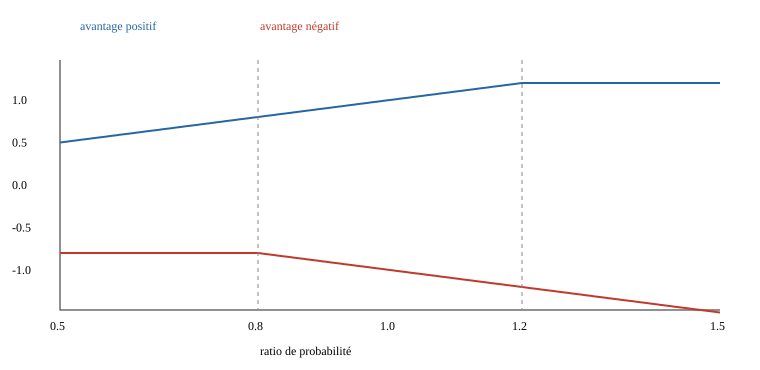

In [5]:
// Pour un avantage négatif, le plateau est à gauche et non à droite.
var clipSvg = new System.Text.StringBuilder(
    "<svg xmlns='http://www.w3.org/2000/svg' width='760' height='370' " +
    "viewBox='0 0 760 370' role='img' aria-label='Objectif clippé selon le signe de l’avantage'>" +
    "<rect width='760' height='370' fill='white'/>" +
    "<path d='M60 60 V310 H720' fill='none' stroke='#222'/>" +
    "<text x='260' y='355'>ratio de probabilité</text>");
foreach (double tick in new[] { -1.0, -.5, 0.0, .5, 1.0 })
    clipSvg.Append($"<text x='12' y='{189-tick*85:F1}'>{tick:F1}</text>");
for (int sign = -1; sign <= 1; sign += 2)
{
    var points = Enumerable.Range(0, 201).Select(i =>
    {
        double ratio = .5 + i / 200.0;
        double a = sign;
        double value = Math.Min(ratio * a, Math.Clamp(ratio, .8, 1.2) * a);
        return $"{60 + (ratio - .5) * 660:F1},{185 - value * 85:F1}";
    });
    string color = sign > 0 ? "#2467a2" : "#c0392b";
    string label = sign > 0 ? "positif" : "négatif";
    int labelX = sign > 0 ? 80 : 260;
    clipSvg.Append($"<polyline fill='none' stroke='{color}' stroke-width='2' " +
                   $"points='{string.Join(" ", points)}'/>");
    clipSvg.Append($"<text x='{labelX}' y='30' fill='{color}'>avantage {label}</text>");
}

foreach (double ratio in new[]
{
    .5,
    .8,
    1.0,
    1.2,
    1.5
}

)
    clipSvg.Append($"<text x='{60 + (ratio - .5) * 660 - 10:F1}' y='330'>{ratio:F1}</text>");
foreach (double bound in new[]
{
    .8,
    1.2
}

)
    clipSvg.Append($"<path d='M{60 + (bound - .5) * 660:F1} 60 V310' stroke='#888' stroke-dasharray='4 4'/>");
clipSvg.Append("</svg>");
display(new PolicySvg(clipSvg.ToString()));

La figure compare les objectifs pour les deux signes ; les pointillés marquent 0,8 et 1,2. Elle illustre un mécanisme local, sans certifier qu’une mise à jour entière reste dans une région KL.

### Exercice 1 — Surrogate clippé

Complétez la perte scalaire à partir des ratios et avantages. Testez les deux signes et les deux côtés de l’intervalle.


In [6]:
#nullable enable
Tensor? PerteClippee(Tensor ratio, Tensor avantage, double epsilon = .2)
{
    return null; // TODO : minimum de r*A et clip(r)*A, puis moyenne négative
}

var candidate = PerteClippee(torch.tensor(new float[] { .6f, 1.4f, .6f, 1.4f }), torch.tensor(new float[] { 1, 1, -1, -1 }));
if (candidate is null)
    Console.WriteLine("Exercice à compléter : surrogate clippé.");
else if (candidate.numel() != 1 || !torch.isfinite(candidate).item<bool>())
    throw new Exception("Perte scalaire finie attendue");
else
    Console.WriteLine($"Perte proposée : {candidate.item<float>():F4}");

Exercice à compléter : surrogate clippé.



warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy



## 4. Actor, critic et PPO

Les deux MLP ont deux couches cachées de 128 neurones, comme en A2C. La collecte mémorise état, action, ancienne log-probabilité et valeur. À chaque mise à jour : normalisation des avantages, quatre époques, mini-lots de 64, objectif clippé, MSE valeur et bonus d’entropie ; Adam utilise 3×10⁻⁴ et le gradient est borné à 0,5.

### GAE et frontières

$\delta_t=r_t+\gamma V(s_{t+1})-V(s_t)$ et $A_t=\delta_t+\gamma\lambda A_{t+1}$ avec $\lambda=0,95$. Sur terminaison, la valeur suivante est nulle. Sur troncature, on bootstrappe depuis l’observation finale mais on **arrête la récursion** avant le reset : sinon l’épisode suivant fuit dans l’avantage. Une coupure d’horizon bootstrappe également. Cette séparation corrige le mélange possible de la version source quand plusieurs épisodes tronqués partagent un horizon ; la dernière collecte partielle est aussi utilisée.


In [7]:
#nullable enable
using System;
using System.Collections.Generic;
using System.Linq;
using TorchSharp;
using static TorchSharp.torch;

public sealed class Networks : IDisposable
{
    public readonly torch.nn.Module<Tensor, Tensor> Actor, Critic;
    public readonly torch.optim.Optimizer Optimizer;
    public Networks(int seed, double lr)
    {
        // Initier les poids avant de séparer les sorties acteur à deux actions et critique scalaire.
        torch.manual_seed(seed);
        Actor = nn.Sequential(nn.Linear(4, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 2));
        Critic = nn.Sequential(nn.Linear(4, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 1));
        Optimizer = optim.Adam(Actor.parameters().Concat(Critic.parameters()), lr: lr);
    }

    public (int action, float logp, float value) Sample(float[] state, Random rng)
    {
        using var scope = torch.NewDisposeScope();
        using var noGrad = torch.no_grad();
        // Calculer la probabilité de l'action 0 ; l'autre action est son complément.
        var input = tensor(state).reshape(1, 4);
        var logs = Actor.forward(input).log_softmax(1);
        float p0 = logs[0, 0].exp().item<float>();
        int action = rng.NextDouble() < p0 ? 0 : 1;
        return (action, logs[0, action].item<float>(), Critic.forward(input).item<float>());
    }

    public float Value(float[] state)
    {
        using var scope = torch.NewDisposeScope();
        using var noGrad = torch.no_grad();
        return Critic.forward(tensor(state).reshape(1, 4)).item<float>();
    }

    public (float loss, float actor, float critic, float entropy) UpdateA2C(List<float[]> states, List<long> actions, float[] returns, bool reinforce, double entropyCoefficient = .01)
    {
        using var scope = torch.NewDisposeScope();
        int n = states.Count;
        // Chaque ligne associe le même état, l'action échantillonnée et son retour cible.
        var x = tensor(states.SelectMany(s => s).ToArray()).reshape(n, 4);
        var act = tensor(actions.ToArray(), dtype: ScalarType.Int64).unsqueeze(1);
        var target = tensor(returns);
        var logs = Actor.forward(x).log_softmax(1);
        var selected = logs.gather(1, act).squeeze(1);
        // Mesurer l'entropie sur les deux actions, indépendamment de l'action tirée.
        var entropy = -(logs.exp() * logs).sum(1).mean();
        var values = Critic.forward(x).squeeze(1);
        // L’actor ne rétropropage pas à travers la baseline du critic.
        var advantage = reinforce ? target : target - values.detach();
        var actorLoss = -(selected * advantage).mean();
        var criticLoss = reinforce ? zeros(1).squeeze() : (values - target).square().mean();
        // REINFORCE garde la perte de politique, l'A2C ajoute valeur et régularisation d'entropie.
        var loss = reinforce ? actorLoss : actorLoss + .5 * criticLoss - entropyCoefficient * entropy;
        Optimizer.zero_grad();
        loss.backward();
        if (!reinforce)
            nn.utils.clip_grad_norm_(Actor.parameters().Concat(Critic.parameters()), 1.0);
        Optimizer.step();
        return (loss.item<float>(), actorLoss.item<float>(), criticLoss.item<float>(), entropy.item<float>());
    }

    public void Dispose()
    {
        Optimizer.Dispose();
        Actor.Dispose();
        Critic.Dispose();
    }
}

public static class Learning
{
    public static float[] Returns(IReadOnlyList<float> rewards, float bootstrap, float gamma = .99f)
    {
        var result = new float[rewards.Count];
        float value = bootstrap;
        // Le parcours à rebours ajoute le retour actualisé du suffixe au gain immédiat.
        for (int t = result.Length - 1; t >= 0; t--)
        {
            value = rewards[t] + gamma * value;
            result[t] = value;
        }

        return result;
    }

    public static double[] TrainA2C(int episodes, int seed, bool reinforce, double entropyCoefficient = .01, Action<int, float>? onEntropy = null)
    {
        using var agent = new Networks(seed, .0007);
        var env = new CartPole();
        var rng = new Random(seed);
        var scores = new double[episodes];
        for (int ep = 0; ep < episodes; ep++)
        {
            // Redémarrer avec une graine dépendante de l'épisode, partagée entre protocoles.
            var state = env.Reset(seed + ep);
            var states = new List<float[]>();
            var actions = new List<long>();
            var rewards = new List<float>();
            bool terminated, truncated;
            do
            {
                var(action, _, _) = agent.Sample(state, rng);
                var step = env.Step(action);
                states.Add(state);
                actions.Add(action);
                rewards.Add((float)step.reward);
                state = step.observation;
                terminated = step.terminated;
                truncated = step.truncated;
            }
            while (!terminated && !truncated);
            // En A2C, seule la fin physique impose une valeur terminale nulle.
            float bootstrap = reinforce || terminated ? 0 : agent.Value(state);
            var result = agent.UpdateA2C(states, actions, Returns(rewards, bootstrap), reinforce, entropyCoefficient);
            if (!float.IsFinite(result.loss))
                throw new ArithmeticException("Perte non finie");
            onEntropy?.Invoke(ep, result.entropy);
            // Le score vaut le nombre de pas puisque CartPole rapporte exactement un par pas.
            scores[ep] = rewards.Count;
        }

        return scores;
    }
}

// Conserver log-probabilité et valeur de collecte pour les cibles de la mise à jour.
public sealed record Transition(float[] State, long Action, float OldLogProbability, float Reward, float Value, float NextValue, bool Terminated, bool Truncated);
public static class PPO
{
    public static float[] Gae(IReadOnlyList<Transition> transitions, float gamma = .99f, float lambda = .95f)
    {
        var result = new float[transitions.Count];
        float gae = 0;
        for (int t = transitions.Count - 1; t >= 0; t--)
        {
            var tr = transitions[t];
            // La troncature garde le bootstrap mais ferme la récursion au reset.
            float delta = tr.Reward + gamma * (tr.Terminated ? 0 : tr.NextValue) - tr.Value;
            gae = delta + gamma * lambda * (tr.Terminated || tr.Truncated ? 0 : gae);
            result[t] = gae;
        }

        return result;
    }

    public static void Update(Networks agent, List<Transition> buffer, double epsilon, Random rng, float lambda = .95f)
    {
        int n = buffer.Count;
        var advantage = Gae(buffer, lambda: lambda);
        // La cible du critique utilise l'avantage brut ; seule la perte de politique reçoit sa version normalisée.
        var returns = advantage.Select((a, i) => a + buffer[i].Value).ToArray();
        double mean = advantage.Average(), std = Math.Sqrt(advantage.Sum(a => (a - mean) * (a - mean)) / Math.Max(1, n - 1));
        for (int i = 0; i < n; i++)
            advantage[i] = (float)((advantage[i] - mean) / (std + 1e-8));
        using var scope = torch.NewDisposeScope();
        var states = tensor(buffer.SelectMany(b => b.State).ToArray()).reshape(n, 4);
        var actions = tensor(buffer.Select(b => b.Action).ToArray(), dtype: ScalarType.Int64).unsqueeze(1);
        var oldLogs = tensor(buffer.Select(b => b.OldLogProbability).ToArray());
        var target = tensor(returns);
        var adv = tensor(advantage);
        // Avant le premier pas Adam, le ratio doit être un à l'arrondi près.
        using (torch.no_grad())
        {
            var initial = agent.Actor.forward(states).log_softmax(1).gather(1, actions).squeeze(1);
            double maxDeviation = (initial - oldLogs).abs().max().item<float>();
            if (maxDeviation > 1e-5)
                throw new Exception($"Ratio initial invalide: {maxDeviation}");
        }

        var indices = Enumerable.Range(0, n).Select(i => (long)i).ToArray();
        for (int epoch = 0; epoch < 4; epoch++)
        {
            // Battre les indices sans remise à chaque époque, en gardant le dernier lot partiel.
            for (int i = n - 1; i > 0; i--)
            {
                int j = rng.Next(i + 1);
                (indices[i], indices[j]) = (indices[j], indices[i]);
            }

            for (int offset = 0; offset < n; offset += 64)
            {
                using var batchScope = torch.NewDisposeScope();
                var idx = tensor(indices.Skip(offset).Take(Math.Min(64, n - offset)).ToArray(), dtype: ScalarType.Int64);
                var sx = states.index_select(0, idx);
                var acts = actions.index_select(0, idx);
                var old = oldLogs.index_select(0, idx);
                var targets = target.index_select(0, idx);
                var advantages = adv.index_select(0, idx);
                var logs = agent.Actor.forward(sx).log_softmax(1);
                var chosen = logs.gather(1, acts).squeeze(1);
                var entropy = -(logs.exp() * logs).sum(1).mean();
                var values = agent.Critic.forward(sx).squeeze(1);
                // Les anciennes log-probabilités restent figées pendant les quatre passes.
                var ratio = (chosen - old).exp();
                var raw = ratio * advantages;
                // Comparer les deux produits signés, car le sens de la borne dépend de l'avantage.
                var surrogate = double.IsPositiveInfinity(epsilon) ? raw : torch.minimum(raw, ratio.clamp(1 - epsilon, 1 + epsilon) * advantages);
                var actorLoss = -surrogate.mean();
                var criticLoss = (values - targets).square().mean();
                var loss = actorLoss + .5 * criticLoss - .01 * entropy;
                agent.Optimizer.zero_grad();
                loss.backward();
                // Détecter une dérive numérique avant de borner et d'appliquer les gradients.
                var parameters = agent.Actor.parameters().Concat(agent.Critic.parameters()).ToArray();
                foreach (var parameter in parameters)
                    if (parameter.grad is not null && !torch.isfinite(parameter.grad).all().item<bool>())
                        throw new ArithmeticException("Gradient PPO non fini");
                nn.utils.clip_grad_norm_(parameters, .5);
                agent.Optimizer.step();
                foreach (var parameter in parameters)
                    if (!torch.isfinite(parameter).all().item<bool>())
                        throw new ArithmeticException("Paramètre PPO non fini");
                if (!float.IsFinite(loss.item<float>()))
                    throw new ArithmeticException("Perte PPO non finie");
            }
        }
    }

    public static double[] Train(int episodes, int seed, double epsilon = .2, int horizon = 2048, float lambda = .95f)
    {
        using var agent = new Networks(seed, .0003);
        var env = new CartPole();
        var rng = new Random(seed);
        var scores = new List<double>();
        var state = env.Reset(seed);
        int score = 0;
        while (scores.Count < episodes)
        {
            var buf = new List<Transition>();
            // La collecte se termine à l'horizon ou au dernier épisode demandé.
            for (int t = 0; t < horizon && scores.Count < episodes; t++)
            {
                var(action, logp, value) = agent.Sample(state, rng);
                var step = env.Step(action);
                // La valeur suivante se calcule avant le reset et reste disponible en cas de troncature.
                float nextValue = step.terminated ? 0 : agent.Value(step.observation);
                buf.Add(new Transition(state, action, logp, (float)step.reward, value, nextValue, step.terminated, step.truncated));
                state = step.observation;
                score++;
                if (step.terminated || step.truncated)
                {
                    scores.Add(score);
                    score = 0;
                    if (scores.Count < episodes)
                        state = env.Reset(seed + scores.Count);
                }
            }

            // Mettre à jour aussi le dernier tampon partiel, même si le budget d'épisodes est atteint.
            if (buf.Count > 0)
                Update(agent, buf, epsilon, rng, lambda);
        }

        return scores.ToArray();
    }
}

Console.WriteLine("Réseaux, collecte PPO, GAE et Adam définis.");

Réseaux, collecte PPO, GAE et Adam définis.



warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply r

### Oracles et invariants

Les cas synthétiques vérifient le signe du clipping, le bootstrap en troncature et l’arrêt de la récursion à la frontière. Chaque mise à jour vérifie les anciennes log-probabilités avant optimisation.


In [8]:
// Les quatre cas couvrent les deux signes et les deux côtés du clipping.
var ratios = torch.tensor(new float[] { .6f, 1.4f, .6f, 1.4f });
var advantagesTest = torch.tensor(new float[] { 1f, 1f, -1f, -1f });
var surrogate = torch.minimum(ratios * advantagesTest, ratios.clamp(.8, 1.2) * advantagesTest);
var expectedSurrogate = torch.tensor(new float[] { .6f, 1.2f, -.8f, -1.4f });
float clippingError = (surrogate - expectedSurrogate).abs().max().item<float>();
var dummyState = new float[]
{
    0,
    0,
    0,
    0
};
var trace = new List<Transition>
{
    new(dummyState, 0, 0, 1, .5f, .7f, false, false),
    new(dummyState, 0, 0, 1, .7f, 2f, false, true),
    new(dummyState, 0, 0, 1, .4f, 0, true, false)
};
var gaeTest = PPO.Gae(trace);
var expectedGae = new float[]
{
    3.33734f,
    2.28f,
    .6f
};
float gaeError = gaeTest.Zip(expectedGae, (a, b) => Math.Abs(a - b)).Max();
if (clippingError > 1e-6 || gaeError > 1e-5)
    throw new Exception("Oracle clipping ou GAE invalide");
Console.WriteLine($"Clipping signes +/− : erreur {clippingError:E2}. GAE terminaison/troncature : erreur {gaeError:E2}, valeurs {string.Join(", ", gaeTest.Select(x => x.ToString("F5")))}.");
Console.WriteLine("Chaque mise à jour vérifie le ratio initial à tolérance 1e-5 et la finitude des gradients et paramètres.");

Clipping signes +/− : erreur 0.00E+000. GAE terminaison/troncature : erreur 0.00E+000, valeurs 3.33734, 2.28000, 0.60000.


Chaque mise à jour vérifie le ratio initial à tolérance 1e-5 et la finitude des gradients et paramètres.



warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply r

### Exercice 2 — Effet de GAE

Comparez $\lambda=0$ et $\lambda=0,95$ sur la même trace, puis entraînez les deux variantes à budget commun.


In [9]:
#nullable enable
(float[] unPas, float[] gae)? ComparerGae(List<Transition> transitions)
{
    return null; // TODO : appeler PPO.Gae avec lambda=0 et lambda=.95
}

var gaeComparison = ComparerGae(trace);
if (gaeComparison is null)
    Console.WriteLine("Exercice à compléter : comparaison de GAE.");
else if (gaeComparison.Value.unPas.Length != trace.Count || gaeComparison.Value.gae.Length != trace.Count)
    throw new Exception("Une valeur par transition attendue");
else
    Console.WriteLine($"Premiers avantages : {gaeComparison.Value.unPas[0]:F4} / {gaeComparison.Value.gae[0]:F4}");

Exercice à compléter : comparaison de GAE.


## 5. Entraînement PPO : 400 épisodes

Le budget est de 400 épisodes et chaque collecte comporte au plus 2 048 transitions. Les points affichés sont mesurés par cette exécution, pas repris du Python.


In [10]:
var mainRewards = PPO.Train(400, 42, .2, 2048);
if (mainRewards.Length != 400)
    throw new Exception("Budget PPO incorrect");
Console.WriteLine($"PPO : {mainRewards.Length} épisodes, moyenne finale 50 : {mainRewards.TakeLast(50).Average():F1}, maximum : {mainRewards.Max():F0}.");

PPO : 400 épisodes, moyenne finale 50 : 481.8, maximum : 500.


### Courbe de l’entraînement

La moyenne mobile réduit le bruit d’un run unique ; elle ne donne pas la dispersion entre graines.


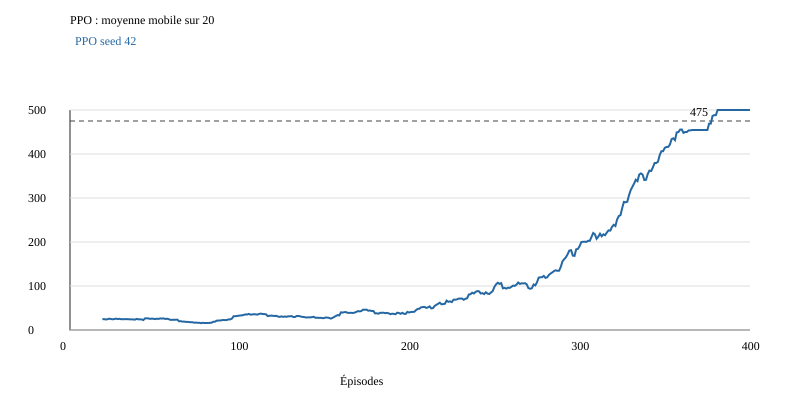

In [11]:
display(new PolicySvg(Charts.Lines("PPO : moyenne mobile sur 20", new Dictionary<string, double[]> { ["PPO seed 42"] = mainRewards }, 20, 475)));

## 6. Ablation du clipping

Deux variantes à budget identique : $\epsilon=0,2$ et absence de clipping, chacune sur 300 épisodes, horizon 2 048 et les cinq graines 42, 0, 1, 7, 99. Les mêmes quatre passes réutilisent les données ; la variante non clippée retire uniquement la borne du surrogate. Les médianes et IQR concernent les moyennes des 50 derniers épisodes.


In [12]:
// Les deux conditions partagent le budget et les cinq graines.
var seeds = new[]
{
    42,
    0,
    1,
    7,
    99
};
// L'expérience paire les graines et ne change que la présence du clipping.
var clippedRuns = new Dictionary<int, double[]>();
var unclippedRuns = new Dictionary<int, double[]>();
foreach (int seed in seeds)
{
    clippedRuns[seed] = PPO.Train(300, seed, .2, 2048);
    unclippedRuns[seed] = PPO.Train(300, seed, double.PositiveInfinity, 2048);
    Console.WriteLine($"graine {seed, 2}: clip {clippedRuns[seed].TakeLast(50).Average():F1}, sans clip {unclippedRuns[seed].TakeLast(50).Average():F1}");
}

foreach (var(name, runs)in new[]
{
    ("clip 0.2", clippedRuns),
    ("sans clip", unclippedRuns)
}

)
{
    // La moyenne des 50 derniers scores réduit le bruit à l'échelle d'une graine.
    var finals = seeds.Select(s => runs[s].TakeLast(50).Average()).ToArray();
    Console.WriteLine($"{name}: médiane {Charts.Quantile(finals, .5):F1}, IQR [{Charts.Quantile(finals, .25):F1}, {Charts.Quantile(finals, .75):F1}]" +
        $", finales {string.Join(", ", finals.Select(x => x.ToString("F1")))}");
}

graine 42: clip 143.1, sans clip 109.6


graine  0: clip 193.3, sans clip 19.3


graine  1: clip 136.8, sans clip 239.7


graine  7: clip 123.1, sans clip 200.4


graine 99: clip 155.6, sans clip 26.8


clip 0.2: médiane 143.1, IQR [136.8, 155.6], finales 143.1, 193.3, 136.8, 123.1, 155.6


sans clip: médiane 109.6, IQR [26.8, 200.4], finales 109.6, 19.3, 239.7, 200.4, 26.8


### Lecture des mesures

Les cinq valeurs de chaque variante décrivent la dispersion des runs, non une garantie. Une graine favorable à la variante non clippée reste possible. Ces résultats à 300 épisodes ne sont pas directement comparables à la trajectoire unique de 400 épisodes.


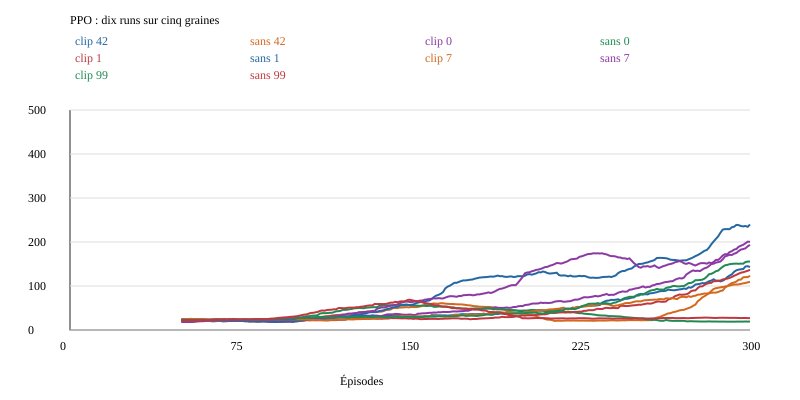

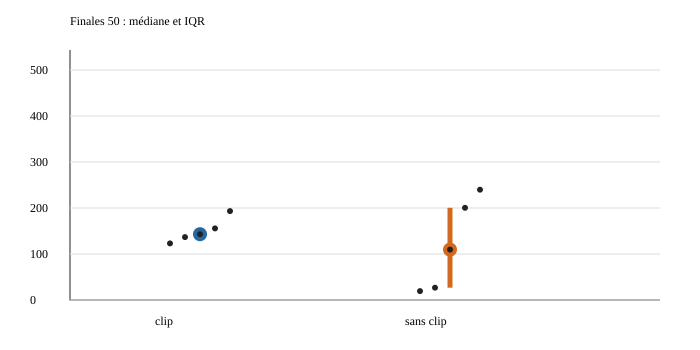

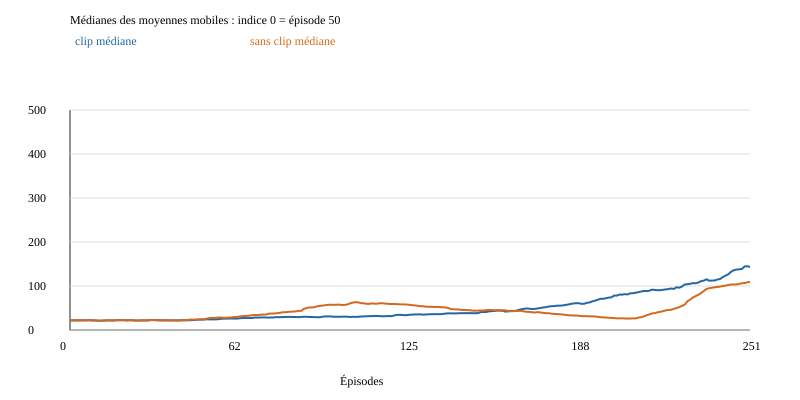

In [13]:
// Comparer les courbes individuelles, puis les médianes et IQR inter-graines.
var allRuns = new Dictionary<string, double[]>();
foreach (int seed in seeds)
{
    allRuns[$"clip {seed}"] = clippedRuns[seed];
    allRuns[$"sans {seed}"] = unclippedRuns[seed];
}

display(new PolicySvg(Charts.Lines("PPO : dix runs sur cinq graines", allRuns, 50)));
// Chaque point de distribution résume un run, plutôt qu'un épisode isolé.
var finalsByCondition = new Dictionary<string, double[]> {
    ["clip"] = seeds.Select(s => clippedRuns[s].TakeLast(50).Average()).ToArray(),
    ["sans clip"] = seeds.Select(s => unclippedRuns[s].TakeLast(50).Average()).ToArray()
};
display(new PolicySvg(Charts.Distribution("Finales 50 : médiane et IQR", finalsByCondition)));
var maClipped = seeds.Select(s => Charts.Moving(clippedRuns[s], 50)).ToArray();
var maUnclipped = seeds.Select(s => Charts.Moving(unclippedRuns[s], 50)).ToArray();
// À épisode fixé, prendre la médiane entre graines sur les séries déjà lissées.
var medianCurves = new Dictionary<string, double[]>
{
    ["clip médiane"] = Enumerable.Range(0, maClipped[0].Length).Select(i => Charts.Quantile(maClipped.Select(c => c[i]).ToArray(), .5)).ToArray(),
    ["sans clip médiane"] = Enumerable.Range(0, maUnclipped[0].Length).Select(i => Charts.Quantile(maUnclipped.Select(c => c[i]).ToArray(), .5)).ToArray()
};
display(new PolicySvg(Charts.Lines("Médianes des moyennes mobiles : indice 0 = épisode 50", medianCurves, 1)));

## 7. Comparer PPO et A2C

A2C utilise une mise à jour par trajectoire ; PPO rejoue des mini-lots sous une politique ancienne. Pour une comparaison équitable, conserver environnement, nombre d’épisodes, graines et métrique ; plusieurs hyperparamètres restent différents.

### Exercice 3 — PPO et A2C à budget commun

Entraînez les deux agents sur 400 épisodes avec les mêmes graines, puis superposez les moyennes mobiles.


In [14]:
#nullable enable
(double[] ppo, double[] a2c)? ComparerPpoA2c(int episodes, int seed)
{
    return null; // TODO : PPO.Train et Learning.TrainA2C à budget commun
}

var comparison = ComparerPpoA2c(400, 42);
if (comparison is null)
    Console.WriteLine("Exercice à compléter : PPO contre A2C.");
else if (comparison.Value.ppo.Length != 400 || comparison.Value.a2c.Length != 400)
    throw new Exception("Deux courbes de 400 épisodes attendues");
else
    Console.WriteLine($"Finales : {comparison.Value.ppo.TakeLast(50).Average():F1} / {comparison.Value.a2c.TakeLast(50).Average():F1}");

Exercice à compléter : PPO contre A2C.


## 8. Application au RLHF et à retenir

Dans un pipeline RLHF utilisant PPO, la politique produit des tokens et un modèle de récompense fournit un signal appris à partir de préférences. Une pénalité KL vers une politique de référence complète souvent l’objectif. Le clipping PPO ne garantit pas, à lui seul, une borne sur toute la divergence ni l’alignement du modèle.

GAE règle un compromis biais–variance par $\lambda$ ; les quatre époques réutilisent le même lot ; les masques de terminaison et de frontière ont des rôles différents.

## Vérifiez votre compréhension

Pourquoi bootstrapper une troncature tout en arrêtant la récursion GAE ?

<details><summary>Éléments de réponse</summary>

La valeur finale estime le futur de l’état avant la limite artificielle, mais le reset commence une nouvelle trajectoire. Propager son avantage dans la précédente mélangerait deux épisodes.

</details>

## Pour aller plus loin

Schulman et al. (2017), *Proximal Policy Optimization Algorithms* ; Schulman et al. (2015), *Generalized Advantage Estimation* ; Sutton et Barto (2018), chapitre 13.
